# Project 03: Student Pass/Fail Predictor

## Problem Statement
Can we predict whether a student will pass or fail based
on study hours and attendance?

## Objective
Build a classification model using Logistic Regression.

## Concepts Covered
- Classification vs. Regression
- Features and target labels
- Train/test splitting
- Feature scaling
- Logistic Regression
- Prediction probabilities
- Confusion matrix and classification metrics

## Tools
Python, NumPy, Pandas, Matplotlib, Scikit-learn

## Important Note
This project uses synthetic data for educational purposes.
It is not a reliable tool for predicting real student outcomes.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
# Make the results reproducible
rng = np.random.default_rng(42)

# Generate data for 120 students
hours_studied = rng.uniform(0, 10, 120)
attendance = rng.uniform(40, 100, 120)

# Generate a hidden performance score with some randomness
performance = (
    0.65 * hours_studied
    + 0.05 * (attendance - 40)
    + rng.normal(0, 1.2, 120)
)

# Assign Pass or Fail labels
results = np.where(performance >= 4.7, "Pass", "Fail")

# Create a DataFrame
df = pd.DataFrame({
    "Hours_Studied": hours_studied.round(2),
    "Attendance_Percent": attendance.round(2),
    "Result": results
})

display(df.head(10))
print("Dataset shape:", df.shape)

,Hours_Studied,Attendance_Percent,Result
0,7.74,75.05,Pass
1,4.39,78.99,Fail
2,8.59,45.07,Fail
3,6.97,64.95,Pass
4,0.94,42.50,Fail
5,9.76,69.64,Pass
6,7.61,59.79,Pass
7,7.86,48.67,Pass
8,1.28,46.20,Fail
9,4.50,75.26,Fail


Dataset shape: (120, 3)


In [3]:
print("Dataset information:")
df.info()

print("\nPass/Fail counts:")
print(df["Result"].value_counts())

print("\nPass/Fail proportions:")
print(
    (df["Result"].value_counts(normalize=True) * 100)
    .round(2)
    .astype(str) + "%"
)

print("\nMissing values:")
print(df.isnull().sum())

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 120 entries, 0 to 119
Data columns (total 3 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Hours_Studied       120 non-null    float64
 1   Attendance_Percent  120 non-null    float64
 2   Result              120 non-null    str    
dtypes: float64(2), str(1)
memory usage: 2.9 KB

Pass/Fail counts:
Result
Pass    66
Fail    54
Name: count, dtype: int64

Pass/Fail proportions:
Result
Pass    55.0%
Fail    45.0%
Name: proportion, dtype: str

Missing values:
Hours_Studied         0
Attendance_Percent    0
Result                0
dtype: int64


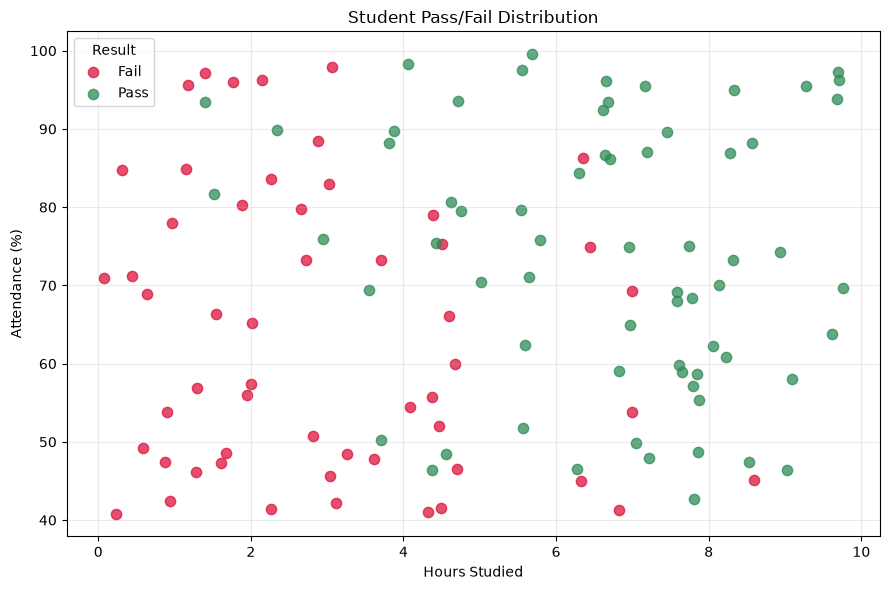

In [4]:
plt.figure(figsize=(9, 6))

for result, color in [("Fail", "crimson"), ("Pass", "seagreen")]:
    subset = df[df["Result"] == result]

    plt.scatter(
        subset["Hours_Studied"],
        subset["Attendance_Percent"],
        label=result,
        color=color,
        alpha=0.75,
        s=55
    )

plt.xlabel("Hours Studied")
plt.ylabel("Attendance (%)")
plt.title("Student Pass/Fail Distribution")
plt.legend(title="Result")
plt.grid(alpha=0.25)
plt.tight_layout()

plt.savefig(
    "student_pass_fail_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [5]:
# Input features
X = df[["Hours_Studied", "Attendance_Percent"]]

# Target label
y = df["Result"]

# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Total samples:", len(df))
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print("\nTraining class distribution:")
print(y_train.value_counts())

print("\nTesting class distribution:")
print(y_test.value_counts())

Total samples: 120
Training samples: 96
Testing samples: 24

Training class distribution:
Result
Pass    53
Fail    43
Name: count, dtype: int64

Testing class distribution:
Result
Pass    13
Fail    11
Name: count, dtype: int64


In [6]:
# Create a pipeline:
# 1. Standardize the input features
# 2. Train the Logistic Regression classifier

model = make_pipeline(
    StandardScaler(),
    LogisticRegression(random_state=42)
)

# Train using the training data
model.fit(X_train, y_train)

print("Model training completed!")
print("Input features:", list(X_train.columns))
print("Classes learned:", model.classes_)

Model training completed!
Input features: ['Hours_Studied', 'Attendance_Percent']
Classes learned: ['Fail' 'Pass']


In [7]:
# Predict Pass/Fail labels
y_pred = model.predict(X_test)

# Compare actual and predicted results
prediction_results = pd.DataFrame({
    "Hours_Studied": X_test["Hours_Studied"].values,
    "Attendance_Percent": X_test["Attendance_Percent"].values,
    "Actual_Result": y_test.values,
    "Predicted_Result": y_pred
})

prediction_results["Correct"] = (
    prediction_results["Actual_Result"]
    == prediction_results["Predicted_Result"]
)

display(prediction_results)

,Hours_Studied,Attendance_Percent,Actual_Result,Predicted_Result,Correct
0,9.71,96.27,Pass,Pass,True
1,9.27,95.51,Pass,Pass,True
2,5.65,71.13,Pass,Pass,True
3,6.70,86.12,Pass,Pass,True
4,6.35,86.32,Fail,Pass,False
5,4.67,59.89,Fail,Fail,True
6,3.62,47.86,Fail,Fail,True
7,1.30,56.87,Fail,Fail,True
8,3.06,97.97,Fail,Pass,False
9,8.23,60.81,Pass,Pass,True


In [8]:
probabilities = model.predict_proba(X_test)

pass_index = list(model.classes_).index("Pass")

prediction_results["Pass_Probability"] = np.round(
    probabilities[:, pass_index], 3
)

display(prediction_results)

,Hours_Studied,Attendance_Percent,Actual_Result,Predicted_Result,Correct,Pass_Probability
0,9.71,96.27,Pass,Pass,True,0.994
1,9.27,95.51,Pass,Pass,True,0.991
2,5.65,71.13,Pass,Pass,True,0.742
3,6.70,86.12,Pass,Pass,True,0.924
4,6.35,86.32,Fail,Pass,False,0.905
5,4.67,59.89,Fail,Fail,True,0.460
6,3.62,47.86,Fail,Fail,True,0.188
7,1.30,56.87,Fail,Fail,True,0.064
8,3.06,97.97,Fail,Pass,False,0.618
9,8.23,60.81,Pass,Pass,True,0.916


In [9]:
# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)

print(f"Accuracy: {accuracy * 100:.2f}%")

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred,
        labels=["Fail", "Pass"],
        zero_division=0
    )
)

Accuracy: 87.50%

Classification Report:
              precision    recall  f1-score   support

        Fail       1.00      0.73      0.84        11
        Pass       0.81      1.00      0.90        13

    accuracy                           0.88        24
   macro avg       0.91      0.86      0.87        24
weighted avg       0.90      0.88      0.87        24



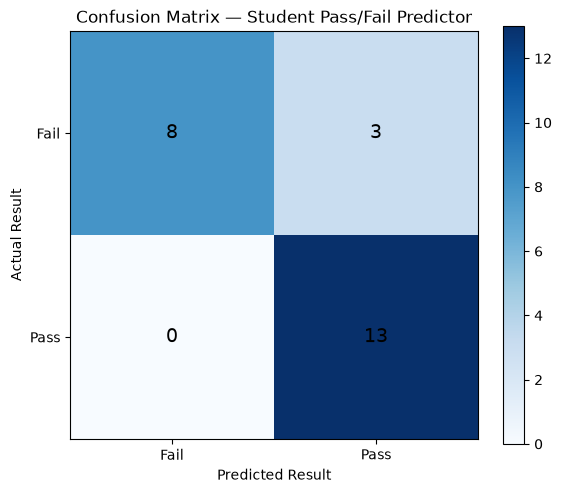

Class order: ['Fail', 'Pass']
[[ 8  3]
 [ 0 13]]


In [10]:
# Explicitly order the classes
labels = ["Fail", "Pass"]

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=labels
)

fig, ax = plt.subplots(figsize=(6, 5))

image = ax.imshow(cm, cmap="Blues")

ax.set_xticks(range(len(labels)))
ax.set_yticks(range(len(labels)))
ax.set_xticklabels(labels)
ax.set_yticklabels(labels)

ax.set_xlabel("Predicted Result")
ax.set_ylabel("Actual Result")
ax.set_title("Confusion Matrix — Student Pass/Fail Predictor")

# Display the counts inside each square
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        ax.text(
            j, i, str(cm[i, j]),
            ha="center",
            va="center",
            fontsize=14
        )

fig.colorbar(image, ax=ax)
plt.tight_layout()

plt.savefig(
    "student_pass_fail_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Class order:", labels)
print(cm)

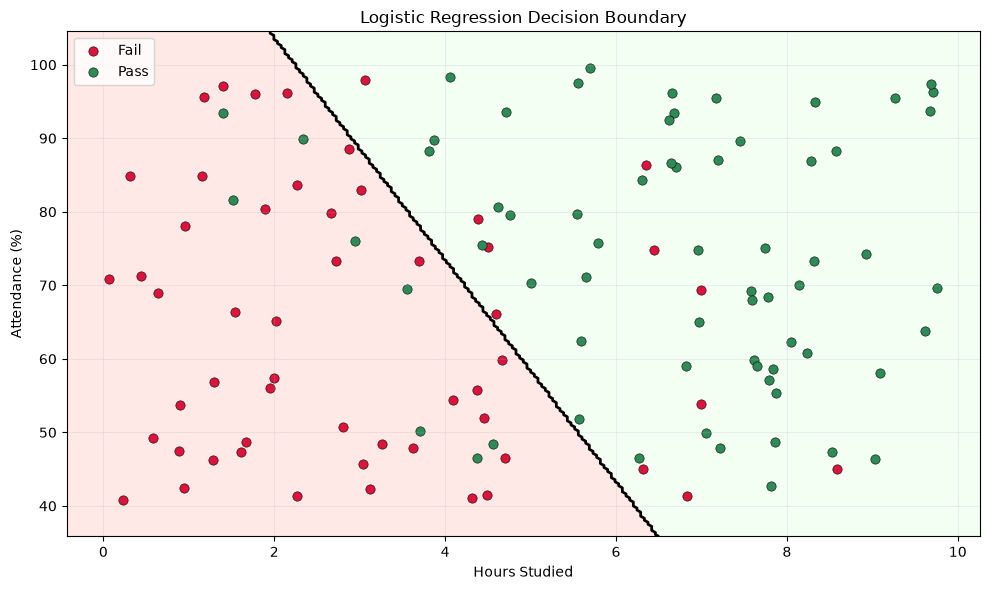

In [11]:
# Define the plotting range
hours_min = df["Hours_Studied"].min() - 0.5
hours_max = df["Hours_Studied"].max() + 0.5

attendance_min = df["Attendance_Percent"].min() - 5
attendance_max = df["Attendance_Percent"].max() + 5

# Create a grid of possible student profiles
xx, yy = np.meshgrid(
    np.linspace(hours_min, hours_max, 250),
    np.linspace(attendance_min, attendance_max, 250)
)

# Convert the grid into a DataFrame
grid = pd.DataFrame({
    "Hours_Studied": xx.ravel(),
    "Attendance_Percent": yy.ravel()
})

# Predict the class for every point on the grid
grid_predictions = model.predict(grid)

# Encode Fail = 0 and Pass = 1
Z = np.where(grid_predictions == "Pass", 1, 0)
Z = Z.reshape(xx.shape)

# Draw the decision regions
plt.figure(figsize=(10, 6))

plt.contourf(
    xx,
    yy,
    Z,
    levels=[-0.5, 0.5, 1.5],
    colors=["mistyrose", "honeydew"],
    alpha=0.8
)

# Draw the decision boundary
plt.contour(
    xx,
    yy,
    Z,
    levels=[0.5],
    colors="black",
    linewidths=2
)

# Plot the actual students
for result, color in [("Fail", "crimson"), ("Pass", "seagreen")]:
    subset = df[df["Result"] == result]

    plt.scatter(
        subset["Hours_Studied"],
        subset["Attendance_Percent"],
        color=color,
        label=result,
        edgecolors="black",
        linewidths=0.4,
        s=45
    )

plt.xlabel("Hours Studied")
plt.ylabel("Attendance (%)")
plt.title("Logistic Regression Decision Boundary")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()

plt.savefig(
    "student_pass_fail_decision_boundary.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [12]:
def predict_student_result(hours, attendance):
    # Validate inputs against the range of our synthetic dataset
    if not 0 <= hours <= 10:
        raise ValueError("Study hours must be between 0 and 10.")

    if not 40 <= attendance <= 100:
        raise ValueError("Attendance must be between 40% and 100%.")

    # Prepare the student's data
    student = pd.DataFrame({
        "Hours_Studied": [hours],
        "Attendance_Percent": [attendance]
    })

    # Predict the class
    prediction = model.predict(student)[0]

    # Get the estimated probability of passing
    probabilities = model.predict_proba(student)[0]
    pass_index = list(model.classes_).index("Pass")
    pass_probability = probabilities[pass_index]

    print(f"Study hours: {hours}")
    print(f"Attendance: {attendance}%")
    print(f"Predicted result: {prediction}")
    print(f"Estimated pass probability: {pass_probability:.1%}")


# Test with a new student
predict_student_result(hours=7, attendance=80)

Study hours: 7
Attendance: 80%
Predicted result: Pass
Estimated pass probability: 91.8%


In [13]:
print("=" * 45)
print("STUDENT PASS/FAIL PREDICTOR — RESULTS")
print("=" * 45)

print(f"Total synthetic samples: {len(df)}")
print(f"Training samples: {len(X_train)}")
print(f"Testing samples: {len(X_test)}")
print(f"Test accuracy: {accuracy * 100:.2f}%")

print("\nConfusion Matrix (Fail, Pass):")
print(cm)

print("\nGenerated visualizations:")
print("- student_pass_fail_distribution.png")
print("- student_pass_fail_confusion_matrix.png")
print("- student_pass_fail_decision_boundary.png")

STUDENT PASS/FAIL PREDICTOR — RESULTS
Total synthetic samples: 120
Training samples: 96
Testing samples: 24
Test accuracy: 87.50%

Confusion Matrix (Fail, Pass):
[[ 8  3]
 [ 0 13]]

Generated visualizations:
- student_pass_fail_distribution.png
- student_pass_fail_confusion_matrix.png
- student_pass_fail_decision_boundary.png
